# Research Comparison: CNN vs RNN vs Vision Transformer vs Low-Noise CNN

This notebook compares the deep learning models in the TESS emotion recognition project:

- CNN
- CNN Low Gaussian Noise
- RNN
- Vision Transformer

The goal is to evaluate each model like a deep learning researcher/data scientist:

- performance
- parameter efficiency
- cost efficiency
- architectural complexity
- training efficiency
- full notebook pipeline runtime
- Pareto trade-offs
- final deployment recommendations

The notebook reads measured values from the model output folders. It does not manually type accuracy or parameter numbers.


## 1. Setup

We import the packages needed for tables, calculations, and plots.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("outputs")
COMPARISON_DIR = OUTPUT_DIR / "deep_model_comparison"
COMPARISON_DISPLAY_NAME = "Deep Model Comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

print("Comparison output folder:", COMPARISON_DIR.resolve())

Comparison output folder: C:\Users\asus\Documents\New project\outputs\deep_model_comparison


## 2. Editable Research Settings

Cloud cost and FLOPs are not always saved automatically.

If you know them, edit the values below. If you do not know them, keep `0.0` or `np.nan`.

In [2]:
# Put your real cloud GPU price here if you know it.
# Example: if the GPU costs $2.50 per hour, write CLOUD_GPU_COST_PER_HOUR = 2.50
CLOUD_GPU_COST_PER_HOUR = 0.0

# Optional FLOPs in billions. Keep np.nan if unknown.
MANUAL_FLOPS_BILLIONS = {
    "CNN": np.nan,
    "CNN Low Gaussian Noise": np.nan,
    "RNN": np.nan,
    "VIT": np.nan,
}

MODEL_REPORT_PATHS = {
    "CNN": OUTPUT_DIR / "cnn" / "model_performance_complexity.csv",
    "CNN Low Gaussian Noise": OUTPUT_DIR / "cnn_low_gaussian_noise" / "model_performance_complexity.csv",
    "RNN": OUTPUT_DIR / "rnn" / "model_performance_complexity.csv",
    "VIT": OUTPUT_DIR / "vit" / "model_performance_complexity.csv",
}

WHOLE_PIPELINE_RUNTIME_PATHS = {
    "CNN": OUTPUT_DIR / "cnn" / "whole_pipeline_runtime.csv",
    "CNN Low Gaussian Noise": OUTPUT_DIR / "cnn_low_gaussian_noise" / "whole_pipeline_runtime.csv",
    "RNN": OUTPUT_DIR / "rnn" / "whole_pipeline_runtime.csv",
    "VIT": OUTPUT_DIR / "vit" / "whole_pipeline_runtime.csv",
}


## 3. Load Measured Model Reports

This cell reads the measured reports from each model.

If a model report is missing, the notebook warns you and continues with the available models.

In [3]:
def load_model_reports(report_paths, runtime_paths=None):
    # Read each model's measured performance/complexity CSV.
    rows = []
    missing = []

    for model_name, path in report_paths.items():
        if path.exists():
            df = pd.read_csv(path)
            if len(df) == 0:
                missing.append((model_name, "empty file"))
                continue

            row = df.iloc[0].to_dict()
            row["model_name"] = model_name
            row["report_path"] = str(path)

            # Prefer the full runtime column if the model notebook already wrote it.
            # Otherwise read the separate whole_pipeline_runtime.csv file if available.
            if "whole_pipeline_runtime_minutes" not in row or pd.isna(row.get("whole_pipeline_runtime_minutes")):
                runtime_path = None if runtime_paths is None else runtime_paths.get(model_name)
                if runtime_path is not None and runtime_path.exists():
                    runtime_df = pd.read_csv(runtime_path)
                    if len(runtime_df) > 0:
                        row["whole_pipeline_runtime_minutes"] = runtime_df.iloc[0].get(
                            "whole_pipeline_runtime_minutes",
                            np.nan,
                        )
                else:
                    row["whole_pipeline_runtime_minutes"] = np.nan

            rows.append(row)
        else:
            missing.append((model_name, str(path)))

    if missing:
        print("Missing or unavailable reports:")
        for model_name, reason in missing:
            print(f"- {model_name}: {reason}")

    if not rows:
        raise FileNotFoundError("No model_performance_complexity.csv files were found.")

    return pd.DataFrame(rows)


raw_reports_df = load_model_reports(MODEL_REPORT_PATHS, WHOLE_PIPELINE_RUNTIME_PATHS)
display(raw_reports_df)


,model_name,test_accuracy,macro_f1,weighted_f1,macro_auc,weighted_auc,total_parameters,trainable_parameters,non_trainable_parameters,model_size_mb,training_minutes,inference_latency_ms_per_sample,report_path,whole_pipeline_runtime_minutes
0,CNN,1.000000,1.000000,1.000000,1.000000,1.000000,1072839,1072615,224,12.358650,0.786400,32.875808,outputs\cnn\model_performance_complexity.csv,NaN
1,CNN Low Gaussian Noise,1.000000,1.000000,1.000000,1.000000,1.000000,1072839,1072615,224,12.358650,0.521763,29.893462,outputs\cnn_low_gaussian_noise\model_performan...,3.440216
2,RNN,0.702381,0.692103,0.692103,0.948922,0.948922,50823,50567,256,0.626884,2.708862,45.335984,outputs\rnn\model_performance_complexity.csv,19.715786
3,VIT,0.969048,0.968989,0.968989,0.998909,0.998909,38375,38375,0,0.613304,0.637017,34.751932,outputs\vit\model_performance_complexity.csv,4.600236


## 4. Efficiency Metrics

We calculate researcher-style efficiency metrics:

- accuracy per million parameters
- accuracy per MB
- accuracy per millisecond of latency
- accuracy per training minute
- accuracy per dollar, if cost is provided
- accuracy per billion FLOPs, if FLOPs are provided

In [4]:
def safe_divide(numerator, denominator):
    # Divide safely. If denominator is missing or zero, return NaN.
    if pd.isna(denominator) or denominator == 0:
        return np.nan
    return numerator / denominator


def add_efficiency_metrics(df):
    df = df.copy()

    if "whole_pipeline_runtime_minutes" not in df.columns:
        df["whole_pipeline_runtime_minutes"] = np.nan

    df["parameters_millions"] = df["total_parameters"] / 1_000_000
    df["training_hours"] = df["training_minutes"] / 60
    df["whole_pipeline_runtime_hours"] = df["whole_pipeline_runtime_minutes"] / 60

    if CLOUD_GPU_COST_PER_HOUR > 0:
        df["training_cost_usd"] = df["training_hours"] * CLOUD_GPU_COST_PER_HOUR
        df["whole_pipeline_cost_usd"] = df["whole_pipeline_runtime_hours"] * CLOUD_GPU_COST_PER_HOUR
    else:
        df["training_cost_usd"] = np.nan
        df["whole_pipeline_cost_usd"] = np.nan

    df["flops_billions"] = df["model_name"].map(MANUAL_FLOPS_BILLIONS)

    df["accuracy_per_million_parameters"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["parameters_millions"]),
        axis=1,
    )
    df["accuracy_per_model_size_mb"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["model_size_mb"]),
        axis=1,
    )
    df["accuracy_per_latency_ms"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["inference_latency_ms_per_sample"]),
        axis=1,
    )
    df["accuracy_per_training_minute"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["training_minutes"]),
        axis=1,
    )
    df["accuracy_per_whole_pipeline_minute"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["whole_pipeline_runtime_minutes"]),
        axis=1,
    )
    df["accuracy_per_dollar"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["training_cost_usd"]),
        axis=1,
    )
    df["accuracy_per_whole_pipeline_dollar"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["whole_pipeline_cost_usd"]),
        axis=1,
    )
    df["accuracy_per_billion_flops"] = df.apply(
        lambda row: safe_divide(row["test_accuracy"], row["flops_billions"]),
        axis=1,
    )

    return df


efficiency_df = add_efficiency_metrics(raw_reports_df)

important_columns = [
    "model_name",
    "test_accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_auc",
    "total_parameters",
    "parameters_millions",
    "model_size_mb",
    "training_minutes",
    "whole_pipeline_runtime_minutes",
    "inference_latency_ms_per_sample",
    "training_cost_usd",
    "whole_pipeline_cost_usd",
    "flops_billions",
    "accuracy_per_million_parameters",
    "accuracy_per_model_size_mb",
    "accuracy_per_latency_ms",
    "accuracy_per_training_minute",
    "accuracy_per_whole_pipeline_minute",
    "accuracy_per_dollar",
    "accuracy_per_whole_pipeline_dollar",
    "accuracy_per_billion_flops",
]

efficiency_table_df = efficiency_df[important_columns].sort_values("test_accuracy", ascending=False)
efficiency_table_df.to_csv(COMPARISON_DIR / "deep_models_efficiency_table.csv", index=False)
display(efficiency_table_df)


,model_name,test_accuracy,macro_f1,weighted_f1,macro_auc,total_parameters,parameters_millions,model_size_mb,training_minutes,whole_pipeline_runtime_minutes,...,whole_pipeline_cost_usd,flops_billions,accuracy_per_million_parameters,accuracy_per_model_size_mb,accuracy_per_latency_ms,accuracy_per_training_minute,accuracy_per_whole_pipeline_minute,accuracy_per_dollar,accuracy_per_whole_pipeline_dollar,accuracy_per_billion_flops
0,CNN,1.000000,1.000000,1.000000,1.000000,1072839,1.072839,12.358650,0.786400,NaN,...,NaN,NaN,0.932106,0.080915,0.030418,1.271618,NaN,NaN,NaN,NaN
1,CNN Low Gaussian Noise,1.000000,1.000000,1.000000,1.000000,1072839,1.072839,12.358650,0.521763,3.440216,...,NaN,NaN,0.932106,0.080915,0.033452,1.916580,0.290679,NaN,NaN,NaN
3,VIT,0.969048,0.968989,0.968989,0.998909,38375,0.038375,0.613304,0.637017,4.600236,...,NaN,NaN,25.252055,1.580044,0.027885,1.521227,0.210652,NaN,NaN,NaN
2,RNN,0.702381,0.692103,0.692103,0.948922,50823,0.050823,0.626884,2.708862,19.715786,...,NaN,NaN,13.820140,1.120431,0.015493,0.259290,0.035625,NaN,NaN,NaN


## 5. Comparative Summary Table

This table is formatted for reports and presentations.

In [5]:
summary_table_df = efficiency_table_df.copy()

display_columns = [
    "model_name",
    "parameters_millions",
    "training_minutes",
    "whole_pipeline_runtime_minutes",
    "training_cost_usd",
    "test_accuracy",
    "macro_f1",
    "macro_auc",
    "accuracy_per_million_parameters",
    "accuracy_per_whole_pipeline_minute",
    "accuracy_per_dollar",
]


def dataframe_to_markdown(df, columns, float_digits=6):
    # Build a Markdown table without requiring the optional tabulate package.
    table = df[columns].copy()
    header = "| " + " | ".join(columns) + " |"
    separator = "| " + " | ".join(["---"] * len(columns)) + " |"
    rows = []

    for _, row in table.iterrows():
        values = []
        for column in columns:
            value = row[column]
            if isinstance(value, float):
                if np.isnan(value):
                    values.append("NaN")
                else:
                    values.append(f"{value:.{float_digits}f}")
            else:
                values.append(str(value))
        rows.append("| " + " | ".join(values) + " |")

    return "\n".join([header, separator] + rows)


markdown_table = dataframe_to_markdown(summary_table_df, display_columns)

with open(COMPARISON_DIR / "deep_models_markdown_table.md", "w", encoding="utf-8") as f:
    f.write(markdown_table)

print(markdown_table)


| model_name | parameters_millions | training_minutes | whole_pipeline_runtime_minutes | training_cost_usd | test_accuracy | macro_f1 | macro_auc | accuracy_per_million_parameters | accuracy_per_whole_pipeline_minute | accuracy_per_dollar |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CNN | 1.072839 | 0.786400 | NaN | NaN | 1.000000 | 1.000000 | 1.000000 | 0.932106 | NaN | NaN |
| CNN Low Gaussian Noise | 1.072839 | 0.521763 | 3.440216 | NaN | 1.000000 | 1.000000 | 1.000000 | 0.932106 | 0.290679 | NaN |
| VIT | 0.038375 | 0.637017 | 4.600236 | NaN | 0.969048 | 0.968989 | 0.998909 | 25.252055 | 0.210652 | NaN |
| RNN | 0.050823 | 2.708862 | 19.715786 | NaN | 0.702381 | 0.692103 | 0.948922 | 13.820140 | 0.035625 | NaN |


## 6. Performance and Efficiency Plots

These plots make the model trade-offs easier to see.

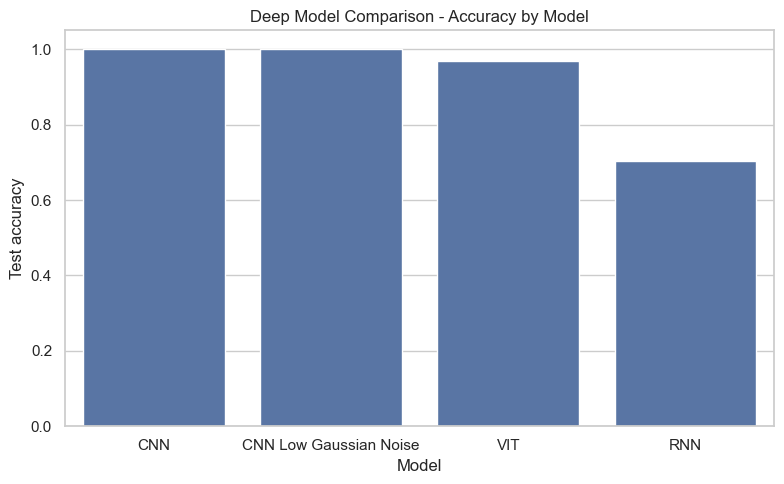

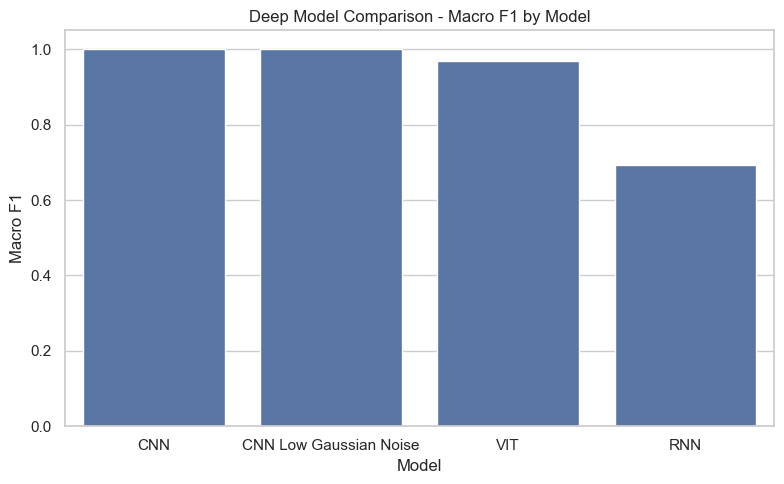

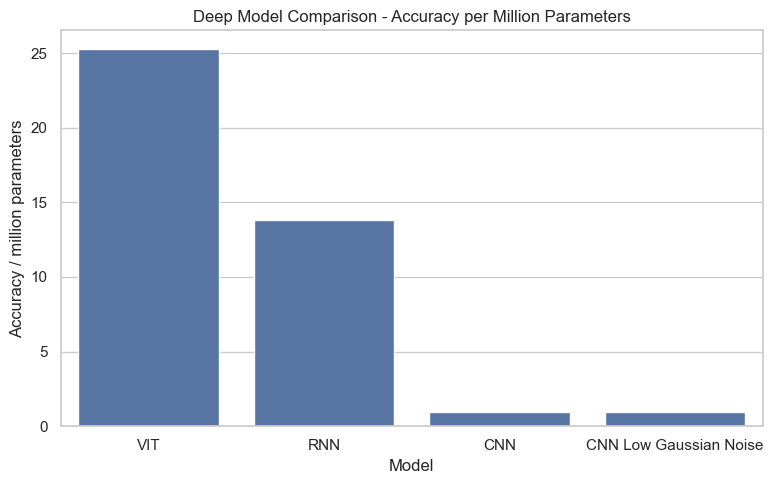

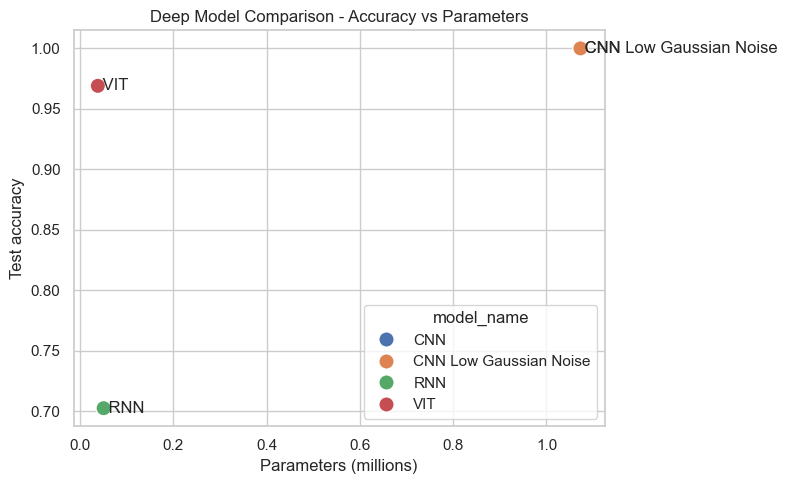

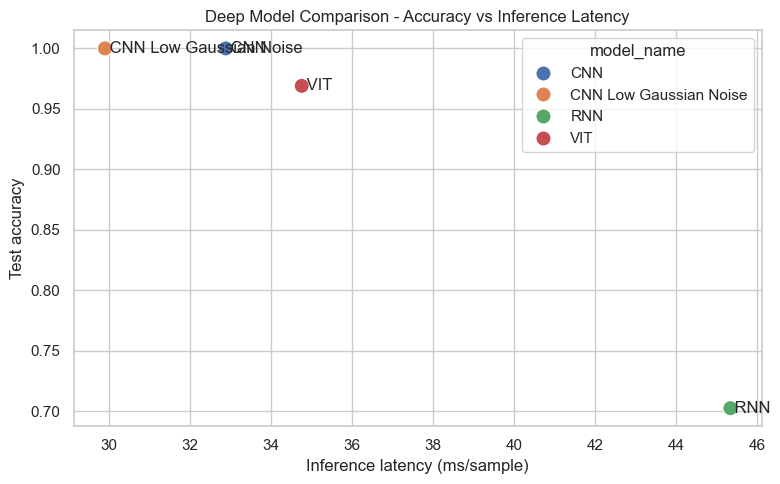

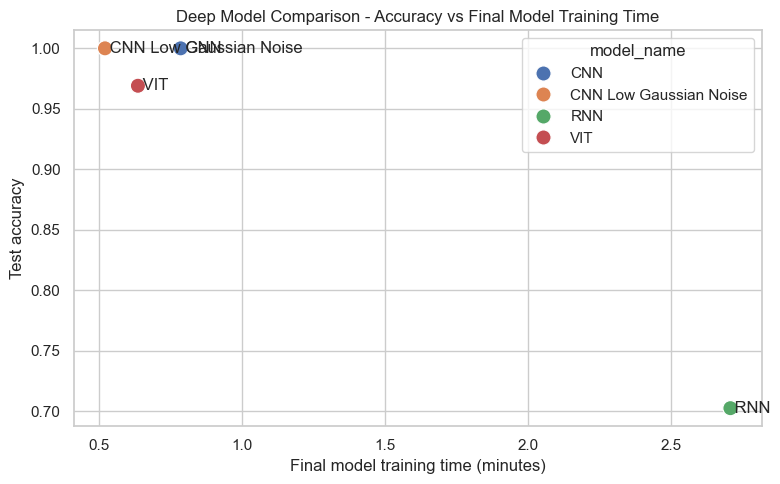

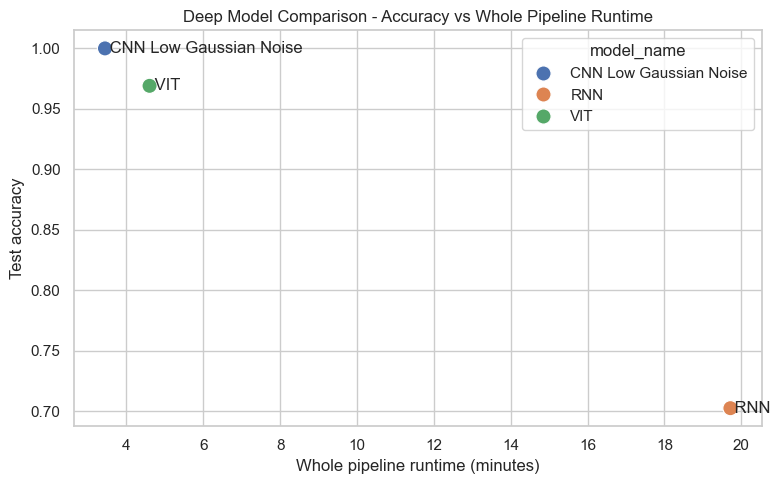

In [6]:
def save_barplot(df, x, y, title, ylabel, filename):
    plt.figure(figsize=(8, 5))
    sns.barplot(data=df, x=x, y=y, order=df.sort_values(y, ascending=False)[x])
    plt.title(f"{COMPARISON_DISPLAY_NAME} - {title}")
    plt.xlabel("Model")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / filename, dpi=200)
    plt.show()


save_barplot(efficiency_df, "model_name", "test_accuracy", "Accuracy by Model", "Test accuracy", "accuracy_by_model.png")
save_barplot(efficiency_df, "model_name", "macro_f1", "Macro F1 by Model", "Macro F1", "macro_f1_by_model.png")
save_barplot(
    efficiency_df,
    "model_name",
    "accuracy_per_million_parameters",
    "Accuracy per Million Parameters",
    "Accuracy / million parameters",
    "accuracy_per_million_params.png",
)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=efficiency_df, x="parameters_millions", y="test_accuracy", hue="model_name", s=120)
for _, row in efficiency_df.iterrows():
    plt.text(row["parameters_millions"], row["test_accuracy"], f" {row['model_name']}", va="center")
plt.title(f"{COMPARISON_DISPLAY_NAME} - Accuracy vs Parameters")
plt.xlabel("Parameters (millions)")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.savefig(COMPARISON_DIR / "accuracy_vs_parameters.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=efficiency_df, x="inference_latency_ms_per_sample", y="test_accuracy", hue="model_name", s=120)
for _, row in efficiency_df.iterrows():
    plt.text(row["inference_latency_ms_per_sample"], row["test_accuracy"], f" {row['model_name']}", va="center")
plt.title(f"{COMPARISON_DISPLAY_NAME} - Accuracy vs Inference Latency")
plt.xlabel("Inference latency (ms/sample)")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.savefig(COMPARISON_DIR / "accuracy_vs_latency.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=efficiency_df, x="training_minutes", y="test_accuracy", hue="model_name", s=120)
for _, row in efficiency_df.iterrows():
    plt.text(row["training_minutes"], row["test_accuracy"], f" {row['model_name']}", va="center")
plt.title(f"{COMPARISON_DISPLAY_NAME} - Accuracy vs Final Model Training Time")
plt.xlabel("Final model training time (minutes)")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.savefig(COMPARISON_DIR / "accuracy_vs_training_time.png", dpi=200)
plt.show()

if efficiency_df["whole_pipeline_runtime_minutes"].notna().any():
    runtime_plot_df = efficiency_df.dropna(subset=["whole_pipeline_runtime_minutes"])
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=runtime_plot_df,
        x="whole_pipeline_runtime_minutes",
        y="test_accuracy",
        hue="model_name",
        s=120,
    )
    for _, row in runtime_plot_df.iterrows():
        plt.text(
            row["whole_pipeline_runtime_minutes"],
            row["test_accuracy"],
            f" {row['model_name']}",
            va="center",
        )
    plt.title(f"{COMPARISON_DISPLAY_NAME} - Accuracy vs Whole Pipeline Runtime")
    plt.xlabel("Whole pipeline runtime (minutes)")
    plt.ylabel("Test accuracy")
    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / "accuracy_vs_whole_pipeline_runtime.png", dpi=200)
    plt.show()
else:
    print("Whole pipeline runtime plot skipped because the runtime CSV files do not exist yet.")


## 7. Pareto Frontier and Trade-off Analysis

A model is Pareto dominated if another model is at least as accurate and also cheaper/smaller/faster.

Here we use a simple complexity score based on:

- parameters
- model size
- latency
- training time
- cost, if provided

,model_name,test_accuracy,macro_f1,weighted_f1,macro_auc,weighted_auc,total_parameters,trainable_parameters,non_trainable_parameters,model_size_mb,...,accuracy_per_whole_pipeline_minute,accuracy_per_dollar,accuracy_per_whole_pipeline_dollar,accuracy_per_billion_flops,complexity_efficiency_score,overall_value_score,pareto_by_parameters,pareto_by_latency,pareto_by_model_size,pareto_by_whole_pipeline_runtime
3,VIT,0.969048,0.968989,0.968989,0.998909,0.998909,38375,38375,0,0.613304,...,0.210652,NaN,NaN,NaN,0.903527,0.949377,True,False,True,False
1,CNN Low Gaussian Noise,1.000000,1.000000,1.000000,1.000000,1.000000,1072839,1072615,224,12.358650,...,0.290679,NaN,NaN,NaN,0.500000,0.850000,True,True,True,True
2,RNN,0.702381,0.692103,0.692103,0.948922,0.948922,50823,50567,256,0.626884,...,0.035625,NaN,NaN,NaN,0.496703,0.638108,False,False,False,False
0,CNN,1.000000,1.000000,1.000000,1.000000,1.000000,1072839,1072615,224,12.358650,...,NaN,NaN,NaN,NaN,NaN,NaN,True,False,True,True


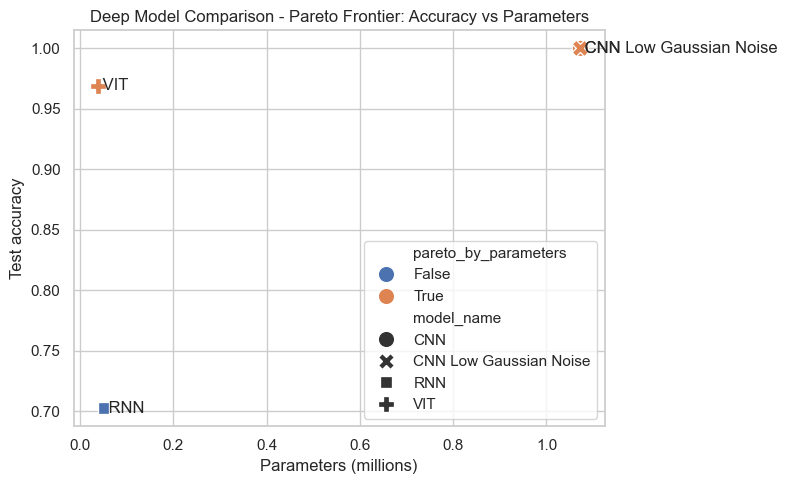

In [7]:
def normalize_lower_is_better(series):
    # Convert a cost-like metric to 0..1 where smaller is better.
    valid = series.dropna()
    if len(valid) == 0 or valid.max() == valid.min():
        return pd.Series(np.ones(len(series)), index=series.index)
    return 1 - ((series - valid.min()) / (valid.max() - valid.min()))


def add_value_scores(df):
    df = df.copy()

    runtime_metric = "whole_pipeline_runtime_minutes"
    if df[runtime_metric].isna().all():
        runtime_metric = "training_minutes"

    score_parts = [
        normalize_lower_is_better(df["parameters_millions"]),
        normalize_lower_is_better(df["model_size_mb"]),
        normalize_lower_is_better(df["inference_latency_ms_per_sample"]),
        normalize_lower_is_better(df[runtime_metric]),
    ]

    if df["whole_pipeline_cost_usd"].notna().any():
        score_parts.append(normalize_lower_is_better(df["whole_pipeline_cost_usd"]))
    elif df["training_cost_usd"].notna().any():
        score_parts.append(normalize_lower_is_better(df["training_cost_usd"]))

    df["complexity_efficiency_score"] = np.mean(score_parts, axis=0)

    # Overall value balances performance and practical efficiency.
    df["overall_value_score"] = (
        0.45 * df["test_accuracy"]
        + 0.25 * df["macro_f1"]
        + 0.30 * df["complexity_efficiency_score"]
    )

    return df


def mark_pareto_frontier(df, accuracy_col="test_accuracy", complexity_col="parameters_millions"):
    # Lower complexity is better; higher accuracy is better.
    pareto_flags = []

    for i, row in df.iterrows():
        dominated = False
        for j, other in df.iterrows():
            if i == j:
                continue
            at_least_as_accurate = other[accuracy_col] >= row[accuracy_col]
            no_more_complex = other[complexity_col] <= row[complexity_col]
            strictly_better = (
                other[accuracy_col] > row[accuracy_col]
                or other[complexity_col] < row[complexity_col]
            )
            if at_least_as_accurate and no_more_complex and strictly_better:
                dominated = True
                break
        pareto_flags.append(not dominated)

    return pareto_flags


analysis_df = add_value_scores(efficiency_df)
analysis_df["pareto_by_parameters"] = mark_pareto_frontier(analysis_df, complexity_col="parameters_millions")
analysis_df["pareto_by_latency"] = mark_pareto_frontier(analysis_df, complexity_col="inference_latency_ms_per_sample")
analysis_df["pareto_by_model_size"] = mark_pareto_frontier(analysis_df, complexity_col="model_size_mb")
analysis_df["pareto_by_whole_pipeline_runtime"] = mark_pareto_frontier(
    analysis_df,
    complexity_col="whole_pipeline_runtime_minutes",
)

analysis_df.to_csv(COMPARISON_DIR / "deep_models_analysis_with_pareto.csv", index=False)
display(analysis_df.sort_values("overall_value_score", ascending=False))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=analysis_df,
    x="parameters_millions",
    y="test_accuracy",
    hue="pareto_by_parameters",
    style="model_name",
    s=140,
)
for _, row in analysis_df.iterrows():
    plt.text(row["parameters_millions"], row["test_accuracy"], f" {row['model_name']}", va="center")
plt.title(f"{COMPARISON_DISPLAY_NAME} - Pareto Frontier: Accuracy vs Parameters")
plt.xlabel("Parameters (millions)")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.savefig(COMPARISON_DIR / "pareto_frontier_accuracy_vs_complexity.png", dpi=200)
plt.show()


## 8. Diminishing Returns and Final Recommendation

This cell writes a researcher-style recommendation summary.

In [8]:
def pct(value):
    return f"{value * 100:.2f}%"


def describe_delta(best_row, simple_row):
    # Compare the most accurate model to the simplest model by parameters.
    accuracy_gain = best_row["test_accuracy"] - simple_row["test_accuracy"]
    extra_params = best_row["total_parameters"] - simple_row["total_parameters"]
    extra_size = best_row["model_size_mb"] - simple_row["model_size_mb"]
    extra_training = best_row["training_minutes"] - simple_row["training_minutes"]
    extra_latency = best_row["inference_latency_ms_per_sample"] - simple_row["inference_latency_ms_per_sample"]

    if pd.notna(best_row.get("whole_pipeline_runtime_minutes")) and pd.notna(simple_row.get("whole_pipeline_runtime_minutes")):
        extra_runtime_text = (
            f", and {best_row['whole_pipeline_runtime_minutes'] - simple_row['whole_pipeline_runtime_minutes']:.3f} "
            "additional whole-pipeline runtime minutes"
        )
    else:
        extra_runtime_text = ""

    return (
        f"Moving from the smallest model by parameter count ({simple_row['model_name']}) "
        f"to the highest-accuracy model ({best_row['model_name']}) changes accuracy by {pct(accuracy_gain)}. "
        f"This requires {extra_params:,.0f} additional parameters, "
        f"{extra_size:.3f} additional MB of saved model size, "
        f"{extra_training:.3f} additional final-training minutes, "
        f"{extra_latency:.3f} additional ms/sample latency"
        f"{extra_runtime_text}."
    )


best_accuracy_row = analysis_df.sort_values("test_accuracy", ascending=False).iloc[0]
best_edge_row = analysis_df.sort_values(
    ["inference_latency_ms_per_sample", "model_size_mb", "parameters_millions"],
    ascending=True,
).iloc[0]
best_value_row = analysis_df.sort_values("overall_value_score", ascending=False).iloc[0]
smallest_param_row = analysis_df.sort_values("parameters_millions", ascending=True).iloc[0]

pareto_models = sorted(
    analysis_df.loc[
        analysis_df["pareto_by_parameters"]
        | analysis_df["pareto_by_latency"]
        | analysis_df["pareto_by_model_size"]
        | analysis_df["pareto_by_whole_pipeline_runtime"],
        "model_name",
    ].unique()
)

summary_lines = [
    "Deep Model Research Comparison Summary",
    "======================================",
    "",
    "Scenario Recommendations:",
    f"1. Resource-constrained / edge deployment: {best_edge_row['model_name']} "
    f"(latency={best_edge_row['inference_latency_ms_per_sample']:.3f} ms/sample, "
    f"size={best_edge_row['model_size_mb']:.3f} MB, accuracy={pct(best_edge_row['test_accuracy'])}).",
    f"2. Maximum accuracy regardless of cost: {best_accuracy_row['model_name']} "
    f"(accuracy={pct(best_accuracy_row['test_accuracy'])}, macro F1={pct(best_accuracy_row['macro_f1'])}).",
    f"3. Best overall value: {best_value_row['model_name']} "
    f"(overall value score={best_value_row['overall_value_score']:.4f}, "
    f"accuracy={pct(best_value_row['test_accuracy'])}).",
    "",
    "Diminishing Returns:",
    describe_delta(best_accuracy_row, smallest_param_row),
    "",
    "Pareto-Optimal Candidates:",
    ", ".join(pareto_models),
    "",
    "Notes:",
    "- Final-training minutes measure the selected model training stage, not full notebook runtime.",
    "- Whole-pipeline runtime is available only after rerunning each model notebook with the new timer cells.",
    "- Accuracy per dollar is NaN when CLOUD_GPU_COST_PER_HOUR is 0.0.",
    "- Accuracy per FLOP is NaN when FLOPs are not provided.",
    "- The comparison uses measured CSV outputs from the model notebooks.",
]

summary_text = "\n".join(summary_lines)

with open(COMPARISON_DIR / "deep_models_tradeoff_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary_text)

print(summary_text)


Deep Model Research Comparison Summary

Scenario Recommendations:
1. Resource-constrained / edge deployment: CNN Low Gaussian Noise (latency=29.893 ms/sample, size=12.359 MB, accuracy=100.00%).
2. Maximum accuracy regardless of cost: CNN (accuracy=100.00%, macro F1=100.00%).
3. Best overall value: VIT (overall value score=0.9494, accuracy=96.90%).

Diminishing Returns:
Moving from the smallest model by parameter count (VIT) to the highest-accuracy model (CNN) changes accuracy by 3.10%. This requires 1,034,464 additional parameters, 11.745 additional MB of saved model size, 0.149 additional final-training minutes, -1.876 additional ms/sample latency.

Pareto-Optimal Candidates:
CNN, CNN Low Gaussian Noise, VIT

Notes:
- Final-training minutes measure the selected model training stage, not full notebook runtime.
- Whole-pipeline runtime is available only after rerunning each model notebook with the new timer cells.
- Accuracy per dollar is NaN when CLOUD_GPU_COST_PER_HOUR is 0.0.
- Accur

## 9. Final Output Checklist

After running this notebook, you should see:

- `outputs/deep_model_comparison/deep_models_efficiency_table.csv`
- `outputs/deep_model_comparison/deep_models_markdown_table.md`
- `outputs/deep_model_comparison/deep_models_tradeoff_summary.txt`
- `outputs/deep_model_comparison/deep_models_analysis_with_pareto.csv`
- `outputs/deep_model_comparison/accuracy_by_model.png`
- `outputs/deep_model_comparison/macro_f1_by_model.png`
- `outputs/deep_model_comparison/accuracy_per_million_params.png`
- `outputs/deep_model_comparison/accuracy_vs_parameters.png`
- `outputs/deep_model_comparison/accuracy_vs_latency.png`
- `outputs/deep_model_comparison/accuracy_vs_training_time.png`
- `outputs/deep_model_comparison/accuracy_vs_whole_pipeline_runtime.png`
- `outputs/deep_model_comparison/pareto_frontier_accuracy_vs_complexity.png`